# AI금융빅데이터플랫폼 공모전 — 전체 속성 EDA

`ABP_CONTEST_DATA.csv`의 **9개 컬럼 전부**를 단변량 → 이변량 → 삼변량 순으로 훑고 그림으로 뽑습니다.

| 컬럼 | 성격 | 이 노트북에서 |
|---|---|---|
| STRD_YYMM | 시간축 (6) | 계절성, 일수 보정 |
| SIDO_NM / CCG_NM | 지역축 (255쌍) | 순위, 분포, 키 중복 |
| GENDER_CD | 구분축 (4) | 남/여/외국인/법인 |
| AGE_CD | 연령축 (7) | **핵심 무기** |
| TP_BUZ_NO / NM | 업종축 (11) | 집밥 vs 외식 |
| amt | 금액 | 규모 |
| cnt | 건수 | **아직 안 쓴 정보** |
| amt/cnt | 건단가 (파생) | 소비 방식 |

그림은 모두 `figs/` 폴더에 PNG로 저장됩니다.

In [1]:
!pip install pandas numpy matplotlib seaborn

## 0. 준비 — 한글 폰트와 데이터 로드

In [2]:
import warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# --- 한글 폰트 (윈도우: 맑은 고딕) ---
if platform.system() == "Windows":
    mpl.rc("font", family="Malgun Gothic")
elif platform.system() == "Darwin":
    mpl.rc("font", family="AppleGothic")
else:
    mpl.rc("font", family="NanumGothic")
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["savefig.bbox"] = "tight"
sns.set_style("whitegrid", {"font.family": mpl.rcParams["font.family"]})

FIG = Path("figs"); FIG.mkdir(exist_ok=True)

def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

print("폰트:", mpl.rcParams["font.family"])

폰트: ['Malgun Gothic']


In [3]:
CSV = "ABP_CONTEST_DATA.csv"

def load(path):
    for enc in ("utf-8-sig", "cp949", "utf-8", "euc-kr"):
        try:
            return pd.read_csv(path, encoding=enc, dtype={"TP_BUZ_NO": str})
        except UnicodeDecodeError:
            continue
    raise ValueError("인코딩 판별 실패")

df = load(CSV)

# 컬럼명 통일
df = df.rename(columns={"TP_BUZ_NO": "TPBUZ_NO", "TP_BUZ_NM": "TPBUZ_NM",
                        "amt": "AMT", "cnt": "CNT"})

# 코드값 정리 (법인이 소문자 x로 들어있음)
df["GENDER_CD"] = df["GENDER_CD"].astype(str).str.strip().str.upper()
df["AGE_CD"]    = df["AGE_CD"].astype(str).str.strip().str.upper()
df["TPBUZ_NM"]  = df["TPBUZ_NM"].astype(str).str.replace(" ", "", regex=False)
df["STRD_YYMM"] = df["STRD_YYMM"].astype(str)

# --- 파생 변수 ---
df["UNIT"] = df["AMT"] / df["CNT"]                       # 건단가
df["GRP2"] = df["TPBUZ_NO"].str[:2]

RETAIL = {"편의점", "대형할인점", "슈퍼마켓"}
df["CH"] = np.where(df["TPBUZ_NM"].isin(RETAIL), "집밥(유통)", "외식")

GENDER_LBL = {"1": "남성", "2": "여성", "3": "외국인", "X": "법인"}
AGE_LBL = {"1": "20대이하", "2": "20대", "3": "30대", "4": "40대",
           "5": "50대", "6": "60대이상", "X": "법인·외국인"}
df["성별"] = df["GENDER_CD"].map(GENDER_LBL)
df["연령"] = df["AGE_CD"].map(AGE_LBL)

KEY = ["SIDO_NM", "CCG_NM"]
AGE_ORDER = ["20대이하", "20대", "30대", "40대", "50대", "60대이상", "법인·외국인"]

print(df.shape)
df.head()

(242574, 14)


,STRD_YYMM,SIDO_NM,CCG_NM,GENDER_CD,AGE_CD,TPBUZ_NO,TPBUZ_NM,AMT,CNT,UNIT,GRP2,CH,성별,연령
0,202605,서울특별시,용산구,2,3,8006,서양음식,734430000,38874,18892.576015,80,외식,여성,30대
1,202605,부산광역시,사상구,2,4,8001,일반한식,424220000,10929,38815.994144,80,외식,여성,40대
2,202601,경상북도,포항시 북구,1,5,4010,편의점,283030000,29848,9482.377379,40,집밥(유통),남성,50대
3,202601,전라남도,여수시,1,6,4010,편의점,204060000,20727,9845.129541,40,집밥(유통),남성,60대이상
4,202606,서울특별시,송파구,1,3,4010,편의점,575120000,86780,6627.333487,40,집밥(유통),남성,30대


## 1. 데이터 구조 점검

먼저 큐브가 실제로 어떤 모양인지 확인합니다. 충진율은 **구조적으로 불가능한 조합**(외국인·법인의 연령)을 빼고 계산해야 정확합니다.

In [4]:
print("=" * 60)
print(df.info(memory_usage="deep"))
print("=" * 60)
print("\n[결측치]")
print(df.isna().sum())
print("\n[중복 행]", df.duplicated().sum())

AXES = ["STRD_YYMM", "SIDO_NM", "CCG_NM", "GENDER_CD", "AGE_CD", "TPBUZ_NO"]
card = {c: df[c].nunique() for c in AXES}
print("\n[축별 고유값]", card)

n_region = df[KEY].drop_duplicates().shape[0]
print(f"\n시군구명 {card['CCG_NM']}개  vs  (시도,시군구) 조합 {n_region}개")
print(f"→ 이름이 겹치는 시군구 {n_region - card['CCG_NM']}개. 반드시 두 컬럼을 키로 쓸 것")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242574 entries, 0 to 242573
Data columns (total 14 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   STRD_YYMM  242574 non-null  object 
 1   SIDO_NM    242574 non-null  object 
 2   CCG_NM     242574 non-null  object 
 3   GENDER_CD  242574 non-null  object 
 4   AGE_CD     242574 non-null  object 
 5   TPBUZ_NO   242574 non-null  object 
 6   TPBUZ_NM   242574 non-null  object 
 7   AMT        242574 non-null  int64  
 8   CNT        242574 non-null  int64  
 9   UNIT       242574 non-null  float64
 10  GRP2       242574 non-null  object 
 11  CH         242574 non-null  object 
 12  성별         242574 non-null  object 
 13  연령         242574 non-null  object 
dtypes: float64(1), int64(2), object(11)
memory usage: 169.6 MB
None

[결측치]
STRD_YYMM    0
SIDO_NM      0
CCG_NM       0
GENDER_CD    0
AGE_CD       0
TPBUZ_NO     0
TPBUZ_NM     0
AMT          0
CNT          0
UNIT         0
GRP2   

## 5개 컬럼 추가 ##

1. UNIT = 금액 ÷ 건수

    한 번 결제할 때 평균 얼마 쓰는지입니다.(건단가)

    원본에는 금액(amt)과 건수(cnt)만 있는데, 이 둘을 나누면 완전히 새로운 정보가 나옵니다
2. GRP2 = 업종 코드 앞 2자리

    업종 코드가 4010, 8001, 8321 이런 식인데, 앞 두 자리(40, 80, 83)가 큰 분류입니다.

    11개 업종을 하나하나 보면 복잡한데, 3개 그룹으로 묶으면 그림이 단순해집니다.

3. CH = 집밥이냐 외식이냐

    11개 업종을 두 덩어리로 나눈 겁니다.

    집밥: 편의점, 대형할인점, 슈퍼마켓 → 재료 사서 집에서 먹음
    외식: 한식, 양식, 중식, 일식, 갈비, 한정식, 스넥, 제과점 → 밖에서 사 먹음

    ### 주관적 ###

4. 성별, 연령 = 코드를 한글로

    GENDER_CD가 1, 2, 3, x로 돼 있고 AGE_CD가 1~6, X로 돼 있어요. 그래프를 그리면 축에 1 2 3 4 5 6만 나와서 뭐가 뭔지 알 수가 없습니다.




In [26]:
chk = df.groupby(['SIDO_NM','CCG_NM'])['AMT'].sum().sort_values(ascending=False)
print((chk.head(20) / 1e8).round(0))

SIDO_NM  CCG_NM 
제주특별자치도  제주시        3617.0
서울특별시    강남구        3407.0
대구광역시    달서구        2328.0
부산광역시    부산진구       2177.0
경기도      시흥시        2010.0
서울특별시    송파구        1918.0
경기도      평택시        1914.0
서울특별시    서초구        1843.0
광주광역시    광산구        1827.0
경상남도     김해시        1811.0
서울특별시    영등포구       1792.0
대구광역시    수성구        1776.0
         북구         1751.0
광주광역시    북구         1704.0
부산광역시    북구         1693.0
서울특별시    마포구        1652.0
부산광역시    해운대구       1650.0
경기도      안산시 단원구    1627.0
         남양주시       1557.0
서울특별시    강서구        1523.0
Name: AMT, dtype: float64


## 시군구 이름이 "가게가 있는 곳"인가, "손님이 사는 곳"인가? ##

1위가 제주시
- 강남구와 수원시의 인구보다 제주시의 인구 수는 약 49만 명으로 사람 수가 작은데 소비액이 1위임
- 그럼 관광객이 와서 쓴 돈인가?
-> 소비 유출입 분석?
- 생각보다 서울이 약함. 오히려 지방 대도시가 강함 -> 그 이유는 뭘까?
    - 수도권 사람들은 온라인 장보기 비중이 높다 — 쿠팡·마켓컬리로 사면 이 데이터에 안 잡히거나 서울 물류센터 주소로 잡힙니다
    - 분구 효과 — 수원시는 장안구·팔달구·영통구·권선구로 나뉘어     있어서 하나씩 보면 작습니다. 반면 달서구는 안 나뉘어 있어요
    - BC카드 점유율 차이 — BC카드는 지방은행 계열이 많아서 지역별로 강세가 다를 수 있습니다

In [27]:
# 1) 인구 대비로 보면 순위가 어떻게 바뀌나 (인구 데이터 없이 임시 확인)
#    → 일단 외국인 비중으로 관광지 여부를 대신 확인
tot = df.groupby(['SIDO_NM','CCG_NM'])['AMT'].sum()
f = df[df['GENDER_CD']=='3'].groupby(['SIDO_NM','CCG_NM'])['AMT'].sum()
print((f/tot*100).sort_values(ascending=False).head(20).round(1))

# 2) 상위 지역들이 집밥형인지 외식형인지
piv = df.pivot_table(index=['SIDO_NM','CCG_NM'], columns='CH', values='AMT', aggfunc='sum')
piv['외식화율'] = piv['외식']/(piv.sum(axis=1))*100
print(piv.loc[chk.head(15).index, '외식화율'].round(1))

SIDO_NM  CCG_NM 
제주특별자치도  제주시        33.0
전라남도     영암군        31.8
제주특별자치도  서귀포시       26.6
충청북도     음성군        26.5
경기도      화성시 만세구    25.2
충청북도     진천군        23.3
경기도      안산시 단원구    21.0
경상북도     고령군        18.2
경기도      시흥시        18.1
충청남도     아산시        16.2
경상북도     성주군        14.5
경상남도     창녕군        13.7
경기도      안성시        13.6
         수원시 팔달구    12.9
         포천시        12.8
         안산시 상록구    12.8
충청남도     논산시        12.6
인천광역시    연수구        12.5
충청북도     증평군        12.4
경기도      김포시        12.3
Name: AMT, dtype: float64
SIDO_NM  CCG_NM
제주특별자치도  제주시       65.0
서울특별시    강남구       77.3
대구광역시    달서구       56.8
부산광역시    부산진구      70.7
경기도      시흥시       49.3
서울특별시    송파구       63.3
경기도      평택시       53.4
서울특별시    서초구       72.8
광주광역시    광산구       56.5
경상남도     김해시       57.2
서울특별시    영등포구      69.9
대구광역시    수성구       65.6
         북구        54.9
광주광역시    북구        59.0
부산광역시    북구        37.0
Name: 외식화율, dtype: float64


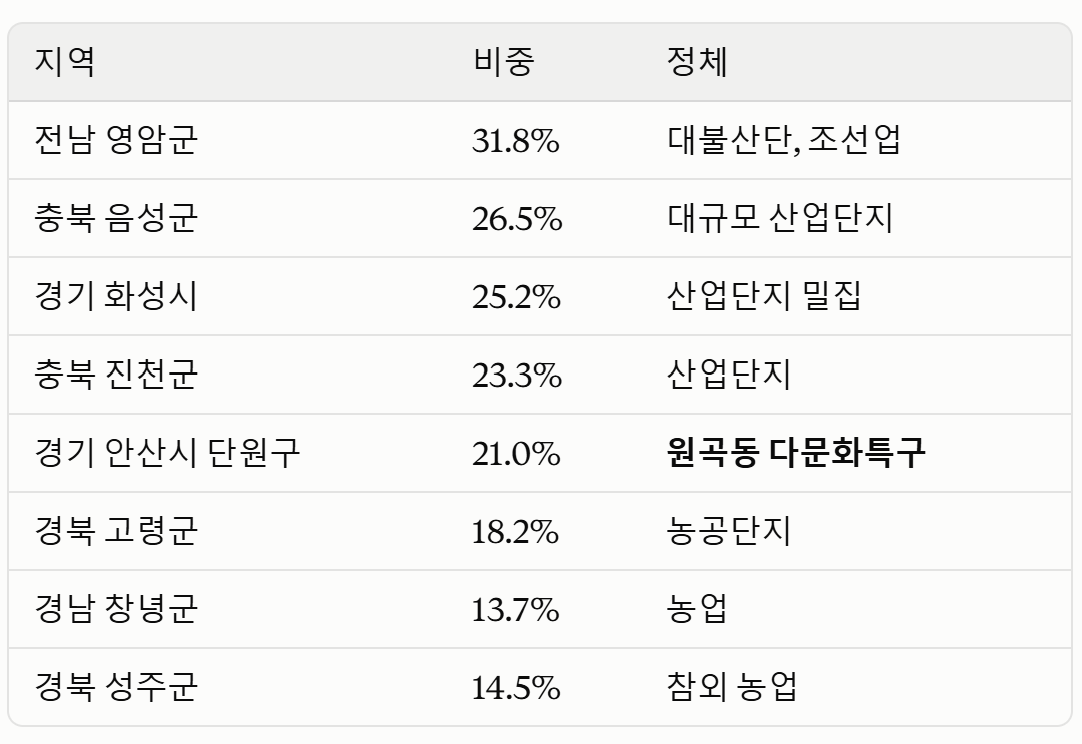

- 제주시 서귀포시는 관광지일 수 있음
- 하지만 나머지는 위의 표의 지역은 관광지라고 하기에 무리가 있음, 외국인 노동자일 가능성이 있음
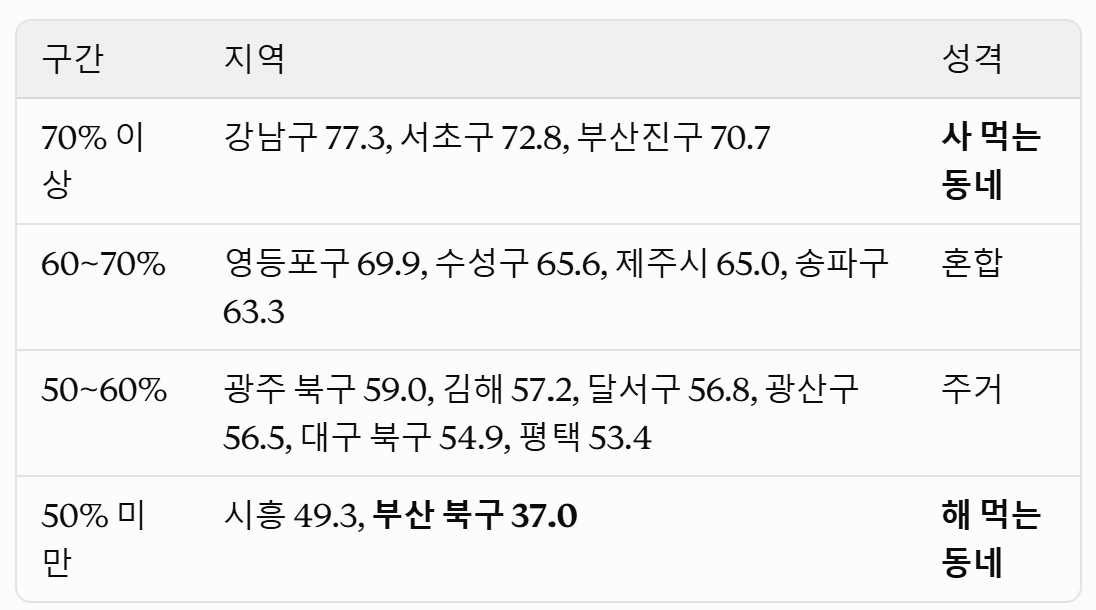



In [28]:
# 외국인 vs 내국인, 업종 구성 비교
f = df[df['GENDER_CD']=='3']
d = df[df['GENDER_CD'].isin(['1','2'])]

comp = pd.DataFrame({
    '내국인': d.groupby('TPBUZ_NM')['AMT'].sum()/d['AMT'].sum()*100,
    '외국인': f.groupby('TPBUZ_NM')['AMT'].sum()/f['AMT'].sum()*100,
})
comp['차이'] = (comp['외국인']-comp['내국인']).round(1)
print(comp.round(1).sort_values('차이', ascending=False))

# 산업단지형 4곳에서 외국인 편의점 의존도
targets = [('전라남도','영암군'),('충청북도','음성군'),
           ('충청북도','진천군'),('경기도','안산시 단원구')]
for t in targets:
    sub = df[(df['SIDO_NM']==t[0]) & (df['CCG_NM']==t[1])]
    for g, lab in [(['3'],'외국인'), (['1','2'],'내국인')]:
        s = sub[sub['GENDER_CD'].isin(g)]
        ret = s[s['CH']=='집밥(유통)']
        cvs = ret[ret['TPBUZ_NM']=='편의점']['AMT'].sum()/ret['AMT'].sum()*100
        print(f"{t[1]:12s} {lab} 편의점의존도 {cvs:5.1f}%")

           내국인   외국인    차이
TPBUZ_NM                  
슈퍼마켓      15.0  25.7  10.7
편의점       14.1  19.9   5.9
중국음식       3.0   4.3   1.3
갈비전문점      0.1   0.0  -0.0
한정식        0.0   0.0  -0.0
제과점        2.8   2.2  -0.6
스넥         3.3   2.6  -0.7
서양음식      11.0  10.2  -0.8
일식회집       2.9   1.6  -1.4
대형할인점     10.1   8.0  -2.1
일반한식      37.8  25.5 -12.3
영암군          외국인 편의점의존도  23.0%
영암군          내국인 편의점의존도  50.4%
음성군          외국인 편의점의존도  41.4%
음성군          내국인 편의점의존도  46.6%
진천군          외국인 편의점의존도  35.8%
진천군          내국인 편의점의존도  43.5%
안산시 단원구      외국인 편의점의존도  32.5%
안산시 단원구      내국인 편의점의존도  32.3%


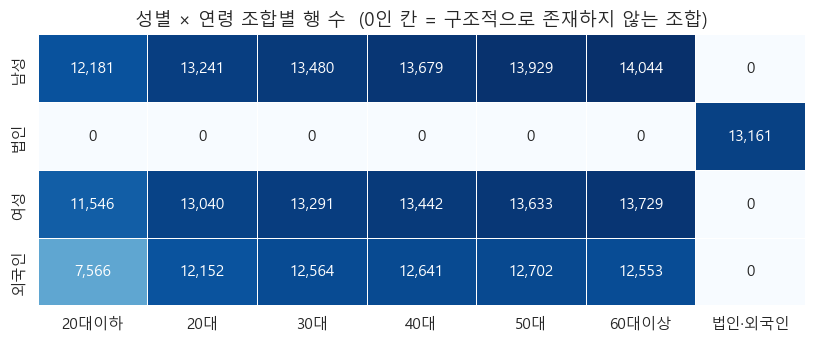

유효 성×연령 조합: 19가지 (4×7=28이 아님)
정확한 충진율 75.9%   vs   부정확한 계산 56.3%


In [5]:
# 성별 × 연령 실제 조합 — 충진율의 정확한 분모를 구하기 위함
ct = pd.crosstab(df["성별"], df["연령"])
ct = ct.reindex(columns=[c for c in AGE_ORDER if c in ct.columns])

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False,
            linewidths=.5, ax=ax)
ax.set_title("성별 × 연령 조합별 행 수  (0인 칸 = 구조적으로 존재하지 않는 조합)")
ax.set_xlabel(""); ax.set_ylabel("")
save("01_gender_age_structure")

valid_combo = int((ct > 0).sum().sum())
denom = card["STRD_YYMM"] * n_region * valid_combo * card["TPBUZ_NO"]
print(f"유효 성×연령 조합: {valid_combo}가지 (4×7=28이 아님)")
naive = len(df) / (card["STRD_YYMM"] * card["CCG_NM"] * 4 * 7 * card["TPBUZ_NO"])
print(f"정확한 충진율 {len(df)/denom:.1%}   vs   부정확한 계산 {naive:.1%}")

## 2. 단변량 — 모든 범주형 축을 3개 지표로

같은 축이라도 **금액(amt) / 건수(cnt) / 건단가(amt÷cnt)** 세 지표에서 순위가 다릅니다.
건단가는 지금까지 한 번도 안 본 정보인데, "한 번에 얼마 쓰는가"를 알려줍니다.

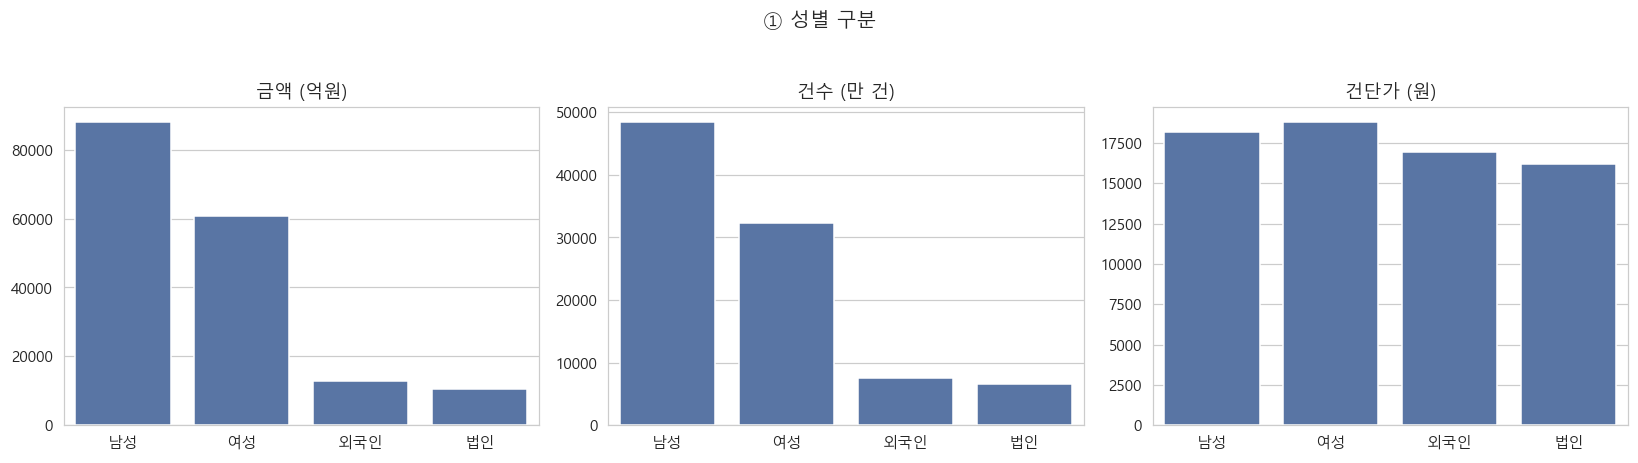

,금액,건수,건단가
성별,,,
남성,8805626620000,484721801,18166.0
여성,6084966970000,323656270,18801.0
외국인,1278089570000,75509726,16926.0
법인,1056216910000,65217271,16195.0


In [6]:
def tri_plot(col, title, order=None, rot=0, figsize=(15, 4)):
    g = df.groupby(col, observed=True).agg(금액=("AMT", "sum"), 건수=("CNT", "sum"))
    g["건단가"] = g["금액"] / g["건수"]
    if order:
        g = g.reindex([o for o in order if o in g.index])
    else:
        g = g.sort_values("금액", ascending=False)

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    specs = [("금액", g["금액"] / 1e8, "억원"),
             ("건수", g["건수"] / 1e4, "만 건"),
             ("건단가", g["건단가"], "원")]
    for ax, (name, s, unit) in zip(axes, specs):
        sns.barplot(x=s.index, y=s.values, ax=ax, color="#4C72B0")
        ax.set_title(f"{name} ({unit})")
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=rot)
    fig.suptitle(title, fontsize=13, y=1.04)
    plt.tight_layout()
    return g

g_gender = tri_plot("성별", "① 성별 구분", order=["남성", "여성", "외국인", "법인"])
save("02_uni_gender")
display(g_gender.round(0))

① 금액은 남성이 많은데 건단가는 여성이 높습니다.

남성이 여성보다 1.45배 많이 썼지만, 한 번에 쓰는 돈은 여성이 더 많습니다(18,801 vs 18,166원).

이건 "남자가 더 많이 먹는다"는 뜻이 아닙니다. 가족 단위 지출에서 결제 명의가 누구냐의 문제일 가능성이 큽니다. 성별 차이를 소비 성향으로 해석하면 위험합니다.

② 법인 건단가가 가장 낮습니다.

법인카드 하면 회식·접대가 떠오르는데, 실제로는 한 번에 쓰는 돈이 4개 중 꼴찌(16,195원)입니다.

의외죠. 이건 법인카드가 큰 회식보다 소액 결제에 더 많이 쓰인다는 신호입니다. 사무실 간식, 커피, 편의점 심부름 같은 것들요. 셀 38에서 이게 확인됩니다.

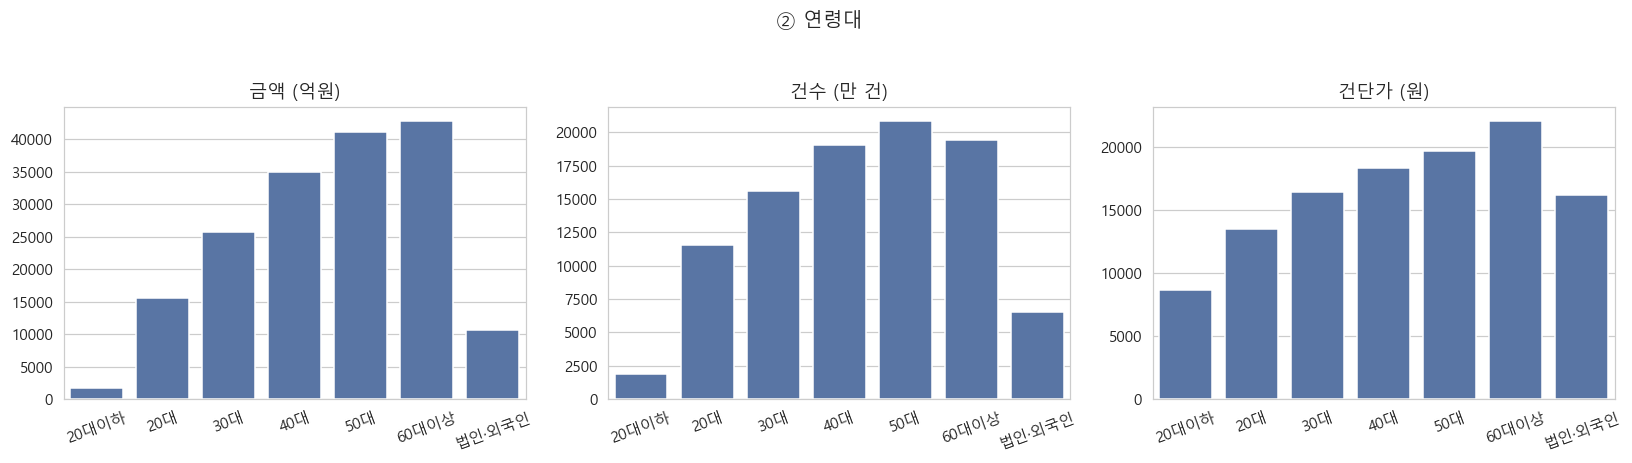

,금액,건수,건단가
연령,,,
20대이하,164574750000,19040909,8643.0
20대,1554573620000,115205282,13494.0
30대,2563522840000,156040206,16429.0
40대,3486600670000,190710302,18282.0
50대,4114387200000,208803382,19705.0
60대이상,4285024080000,194087716,22078.0
법인·외국인,1056216910000,65217271,16195.0


In [7]:
g_age = tri_plot("연령", "② 연령대", order=AGE_ORDER, rot=20)
save("03_uni_age")
display(g_age.round(0))

1. 건단가가 나이 따라 완벽하게 계단처럼 올라감
2. 먹거리 소비의 주력은 5060임

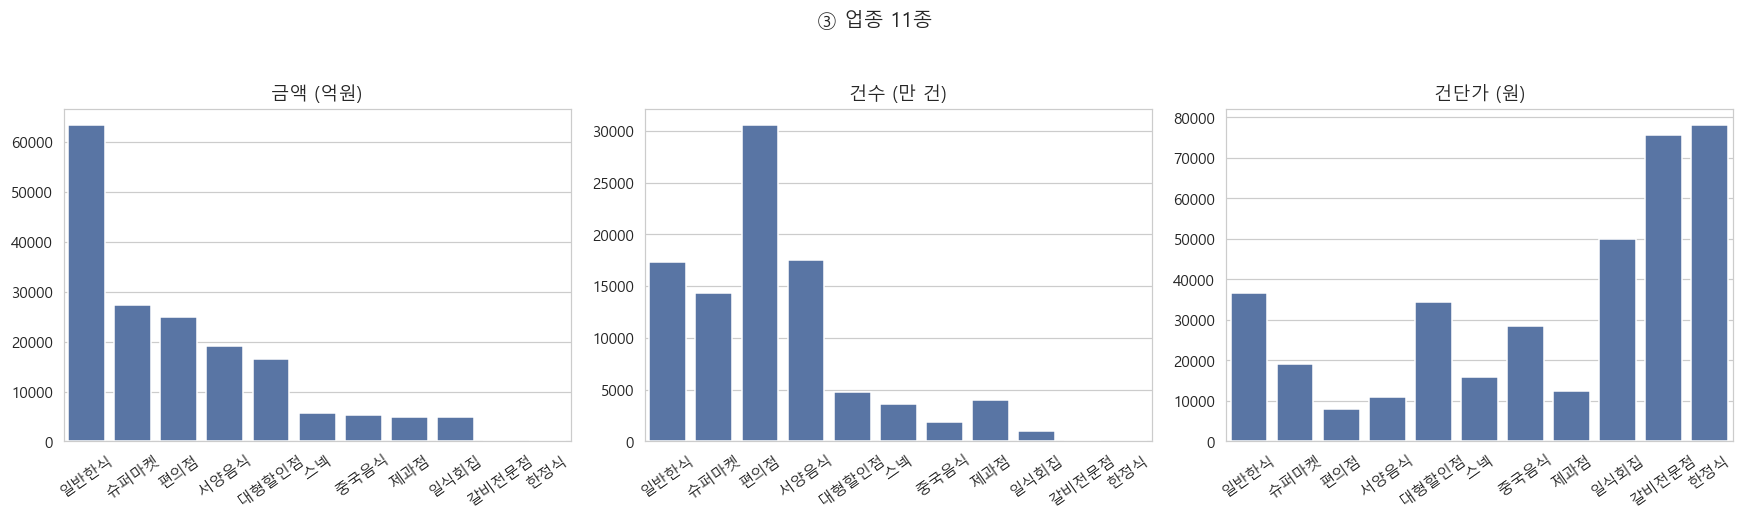

,금액,건수,건단가
TPBUZ_NM,,,
일반한식,6348450610000,173301016,36633.0
슈퍼마켓,2723898860000,143282938,19011.0
편의점,2483898980000,306005921,8117.0
서양음식,1916074350000,174739374,10965.0
대형할인점,1654789730000,47906339,34542.0
스넥,571506890000,35722693,15998.0
중국음식,529612890000,18567799,28523.0
제과점,498417820000,39671152,12564.0
일식회집,487750290000,9769473,49926.0


In [8]:
g_buz = tri_plot("TPBUZ_NM", "③ 업종 11종", rot=35, figsize=(16, 4.5))
save("04_uni_buz")
display(g_buz.round(0))

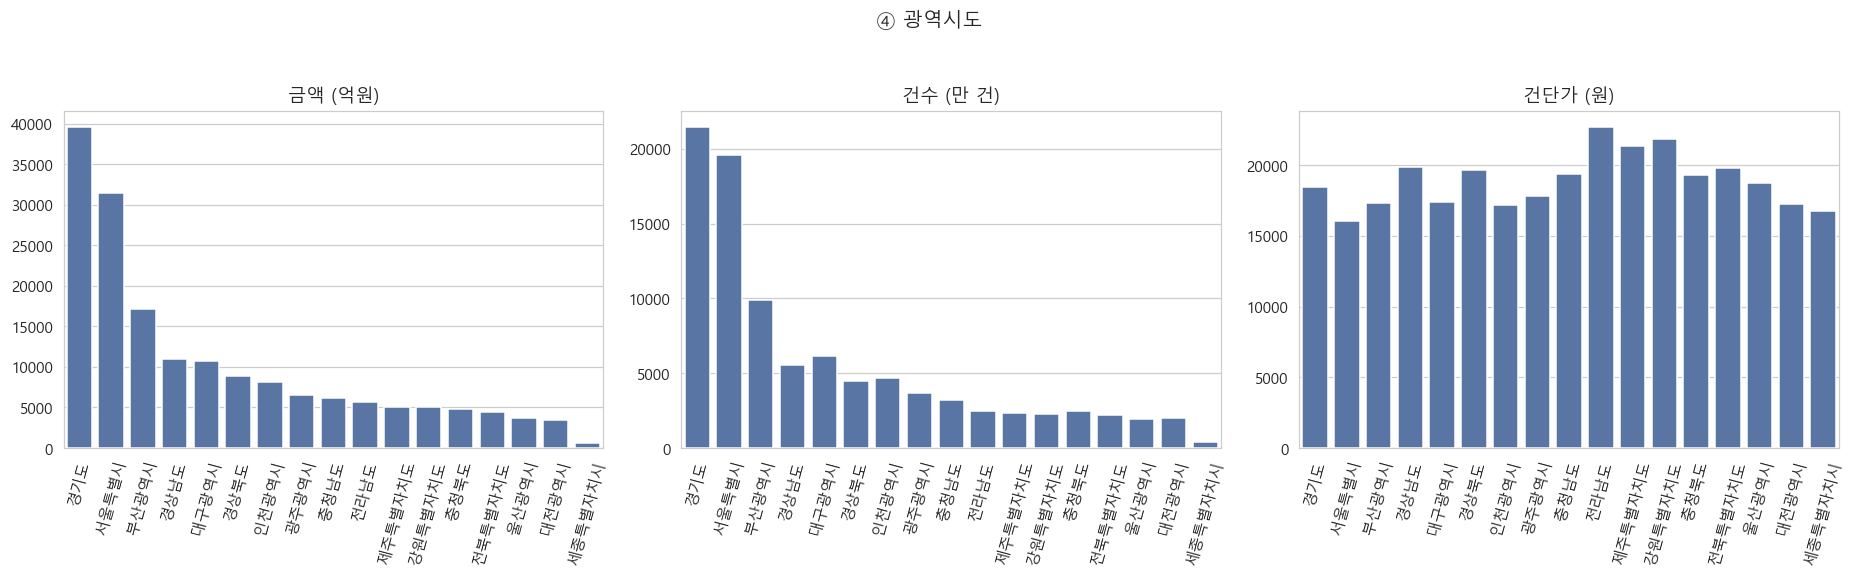

In [9]:
g_sido = tri_plot("SIDO_NM", "④ 광역시도", rot=75, figsize=(17, 5))
save("05_uni_sido")

### 금액·건수·건단가 분포

셀 단위 값이 어떻게 퍼져 있는지 봅니다. 금액과 건수는 꼬리가 매우 길어 로그 스케일로 봅니다.

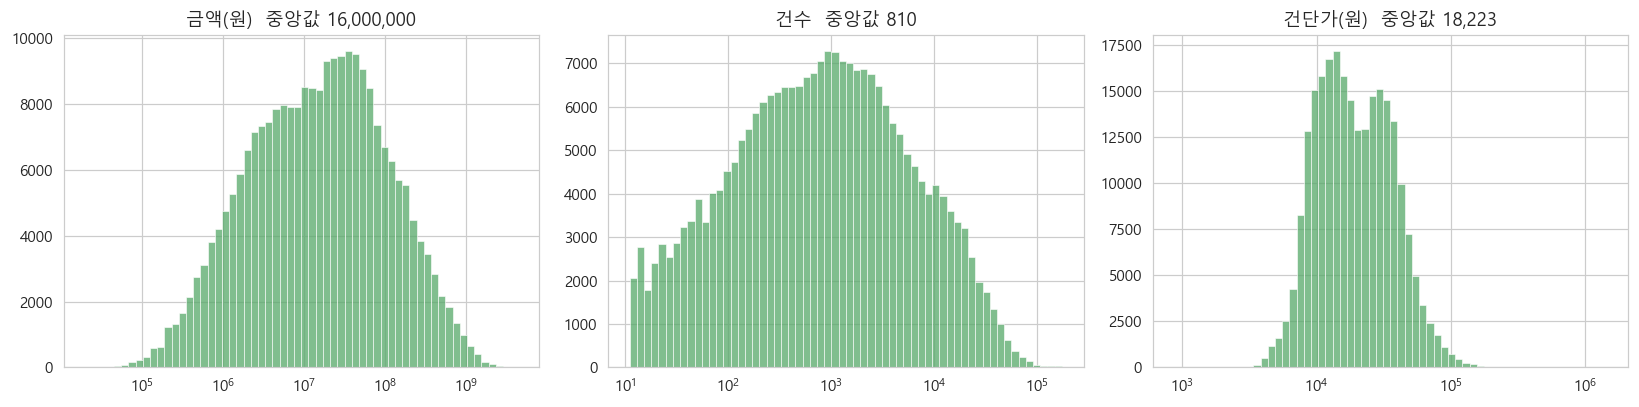

,AMT,CNT,UNIT
count,2.425740e+05,242574.0,242574.0
mean,7.100885e+07,3913.0,23781.0
std,1.653747e+08,8561.0,18481.0
min,2.000000e+04,11.0,870.0
25%,3.440000e+06,178.0,11513.0
50%,1.600000e+07,810.0,18223.0
75%,6.045000e+07,3330.0,31262.0
max,4.247220e+09,174529.0,1445556.0


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, lab in zip(axes, ["AMT", "CNT", "UNIT"], ["금액(원)", "건수", "건단가(원)"]):
    sns.histplot(df[col], bins=60, ax=ax, color="#55A868", log_scale=(True, False))
    ax.set_title(f"{lab}  중앙값 {df[col].median():,.0f}")
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
save("06_distributions")

display(df[["AMT", "CNT", "UNIT"]].describe().round(0))

## 3. 시간축 — 계절성과 일수 보정

2월이 낮은 이유가 **설 연휴인지 28일밖에 없어서인지** 구분해야 합니다.
하루 평균으로 바꿔보면 답이 나옵니다.

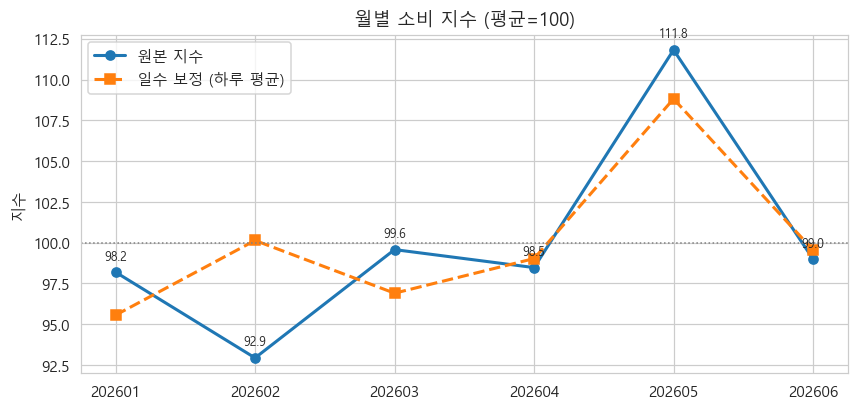

,원본,일수보정,차이
STRD_YYMM,,,
202601,98.2,95.6,-2.6
202602,92.9,100.1,7.2
202603,99.6,96.9,-2.7
202604,98.5,99.0,0.5
202605,111.8,108.8,-3.0
202606,99.0,99.6,0.6


원본 변동폭 18.9p → 보정 후 13.3p
→ 보정 후에도 10p를 넘으면 6개월 시계열로 성장/쇠퇴를 논하지 말 것


In [11]:
DAYS = {"202601": 31, "202602": 28, "202603": 31,
        "202604": 30, "202605": 31, "202606": 30}

m = df.groupby("STRD_YYMM")["AMT"].sum().sort_index()
raw = m / m.mean() * 100
d = pd.Series(DAYS).reindex(m.index)
adj = (m / d)
adj = adj / adj.mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(raw.index, raw.values, "o-", label="원본 지수", lw=2)
ax.plot(adj.index, adj.values, "s--", label="일수 보정 (하루 평균)", lw=2)
ax.axhline(100, color="gray", ls=":", lw=1)
for x, y in zip(raw.index, raw.values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)
ax.set_title("월별 소비 지수 (평균=100)")
ax.set_ylabel("지수"); ax.legend()
save("07_seasonality")

comp = pd.DataFrame({"원본": raw.round(1), "일수보정": adj.round(1)})
comp["차이"] = (comp["일수보정"] - comp["원본"]).round(1)
display(comp)
print(f"원본 변동폭 {raw.max()-raw.min():.1f}p → 보정 후 {adj.max()-adj.min():.1f}p")
print("→ 보정 후에도 10p를 넘으면 6개월 시계열로 성장/쇠퇴를 논하지 말 것")

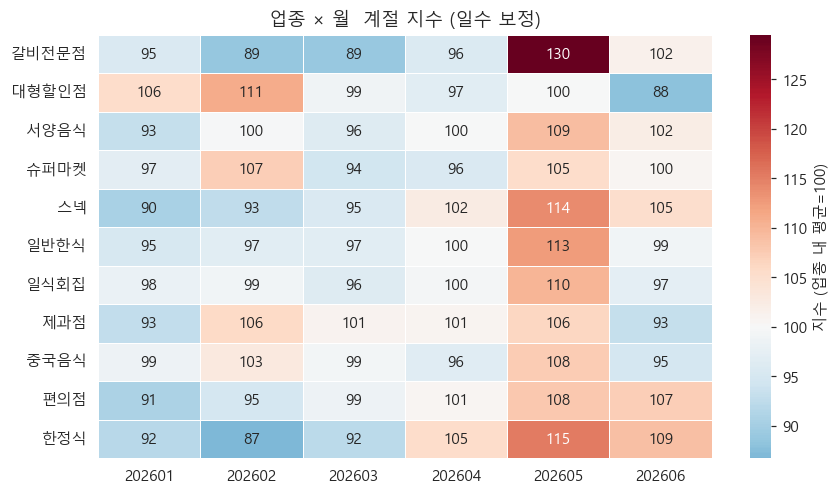

계절 변동이 큰 업종:
TPBUZ_NM
갈비전문점    40.8
한정식      28.5
스넥       23.5
대형할인점    23.1
일반한식     17.5
편의점      17.1
서양음식     15.9
일식회집     13.8
제과점      13.5
슈퍼마켓     12.7
중국음식     12.6


In [12]:
# 업종별 계절 패턴 — 어떤 업종이 계절을 타는가
piv = df.pivot_table(index="TPBUZ_NM", columns="STRD_YYMM", values="AMT", aggfunc="sum")
piv = piv.div(pd.Series(DAYS), axis=1)             # 일수 보정
piv_idx = piv.div(piv.mean(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(piv_idx.round(1), annot=True, fmt=".0f", center=100,
            cmap="RdBu_r", linewidths=.5, ax=ax,
            cbar_kws={"label": "지수 (업종 내 평균=100)"})
ax.set_title("업종 × 월  계절 지수 (일수 보정)")
ax.set_xlabel(""); ax.set_ylabel("")
save("08_buz_month_heatmap")

volat = (piv_idx.max(axis=1) - piv_idx.min(axis=1)).sort_values(ascending=False)
print("계절 변동이 큰 업종:")
print(volat.round(1).to_string())

대형할인점 23.1

대형할인점은 전체의 9.6%로 충분히 큽니다. 그런데 변동이 23.1p로 큽니다.

이건 명절 장보기가 진짜로 존재한다는 증거입니다. 설 연휴 전에 마트에서 크게 장 보고, 평소엔 안 가는 패턴이죠.

가장 안정적인 건 슈퍼마켓·중국음식

12.7과 12.6. 계절을 거의 안 탑니다. 매일 필요한 것들이니까요.

## 4. 지역축 — 반드시 (시도, 시군구) 두 컬럼을 키로

`CCG_NM`만으로 묶으면 서울 중구·부산 중구·대구 중구가 하나로 합쳐집니다.

In [13]:
dupe = (df[KEY].drop_duplicates().groupby("CCG_NM").size()
        .sort_values(ascending=False))
dupe = dupe[dupe > 1]
print(f"여러 시도에 존재하는 시군구명: {len(dupe)}개")
display(dupe.to_frame("시도 수").T)

# 잘못된 집계 vs 올바른 집계 비교
wrong = df.groupby("CCG_NM")["AMT"].sum().sort_values(ascending=False).head(10)
right = df.groupby(KEY)["AMT"].sum().sort_values(ascending=False).head(10)
print("\n[잘못된 키] CCG_NM 단독")
print((wrong / 1e8).round(0).to_string())
print("\n[올바른 키] SIDO_NM + CCG_NM")
print((right / 1e8).round(0).to_string())

여러 시도에 존재하는 시군구명: 7개


CCG_NM,동구,중구,서구,북구,남구,강서구,고성군
시도 수,6,6,5,4,4,2,2



[잘못된 키] CCG_NM 단독
CCG_NM
북구      5772.0
중구      5207.0
서구      5074.0
동구      3939.0
제주시     3617.0
남구      3612.0
강남구     3407.0
강서구     2332.0
달서구     2328.0
부산진구    2177.0

[올바른 키] SIDO_NM + CCG_NM
SIDO_NM  CCG_NM
제주특별자치도  제주시       3617.0
서울특별시    강남구       3407.0
대구광역시    달서구       2328.0
부산광역시    부산진구      2177.0
경기도      시흥시       2010.0
서울특별시    송파구       1918.0
경기도      평택시       1914.0
서울특별시    서초구       1843.0
광주광역시    광산구       1827.0
경상남도     김해시       1811.0


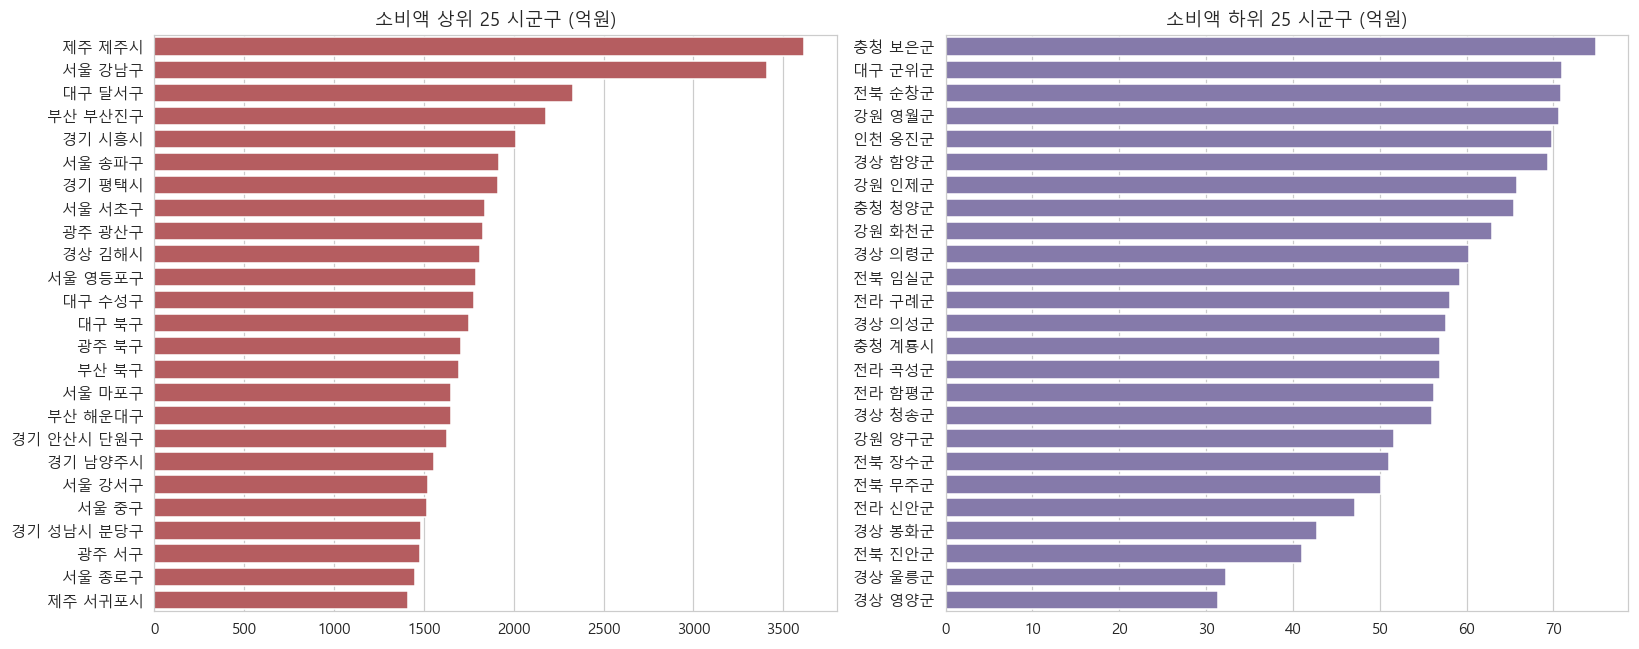

>> 서울 중구·종로구가 상위권이면 CCG_NM = '가맹점 소재지'
>> 인구 순서와 거의 같으면 CCG_NM = '고객 거주지'


In [14]:
sgg = df.groupby(KEY)["AMT"].sum().sort_values(ascending=False)
sgg.index = [f"{s.replace('특별자치도','').replace('특별시','').replace('광역시','')[:2]} {c}"
             for s, c in sgg.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(y=sgg.head(25).index, x=sgg.head(25).values / 1e8,
            ax=axes[0], color="#C44E52")
axes[0].set_title("소비액 상위 25 시군구 (억원)")
sns.barplot(y=sgg.tail(25).index, x=sgg.tail(25).values / 1e8,
            ax=axes[1], color="#8172B2")
axes[1].set_title("소비액 하위 25 시군구 (억원)")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout()
save("09_sgg_rank")

print(">> 서울 중구·종로구가 상위권이면 CCG_NM = '가맹점 소재지'")
print(">> 인구 순서와 거의 같으면 CCG_NM = '고객 거주지'")

제주시(3,617억) — 인구 49만인데 전국 1위. 인구 56만 강남구보다 많습니다. 지역 주민만으로는 설명이 안 됩니다.

서울 중구·종로구가 20위 안에 없습니다. 제가 "오피스 상권이 상위권일 것"이라고 예상했는데 빗나갔어요.

이유는 이 데이터에 마트·슈퍼·편의점이 포함되기 때문입니다. 중구·종로구는 식당은 많지만 사는 사람이 적어서 장보기 소비가 거의 없습니다. 반면 송파·강서·시흥·남양주는 식당은 평범해도 장보기 금액이 큽니다.

즉 이 데이터는 오피스 상권보다 주거지에 유리하게 기울어 있습니다. 먹거리 데이터라는 성격이 순위에 그대로 반영된 거예요.

## 5. 교차 분석 — 여기부터가 이 데이터의 진짜 가치

축 하나씩 보는 건 누구나 합니다. **연령 × 업종 × 지역**을 동시에 봐야 남들이 못 본 게 나옵니다.

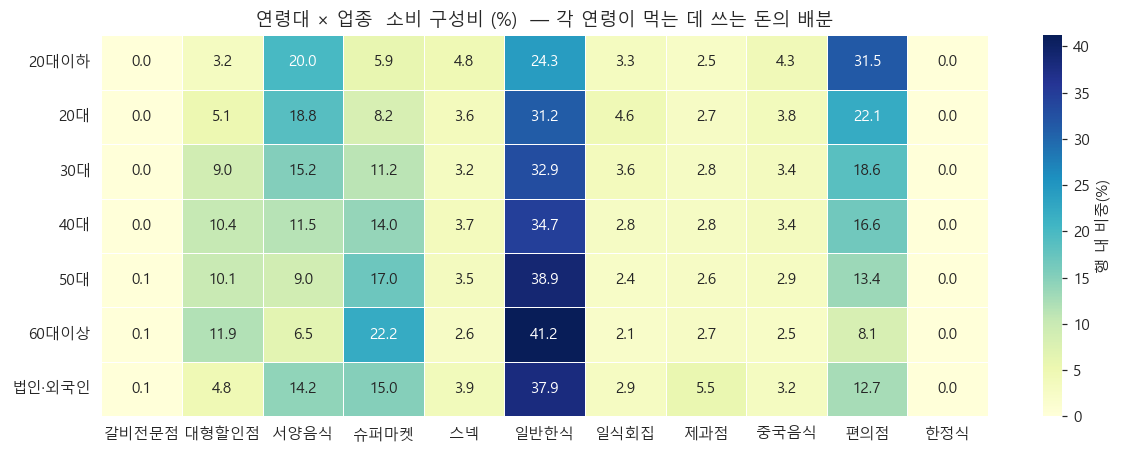

In [15]:
# 연령 × 업종 : 구성비
ct1 = pd.crosstab(df["연령"], df["TPBUZ_NM"], values=df["AMT"],
                  aggfunc="sum", normalize="index") * 100
ct1 = ct1.reindex([a for a in AGE_ORDER if a in ct1.index])

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(ct1.round(1), annot=True, fmt=".1f", cmap="YlGnBu",
            linewidths=.5, ax=ax, cbar_kws={"label": "행 내 비중(%)"})
ax.set_title("연령대 × 업종  소비 구성비 (%)  — 각 연령이 먹는 데 쓰는 돈의 배분")
ax.set_xlabel(""); ax.set_ylabel("")
save("10_age_buz_share")

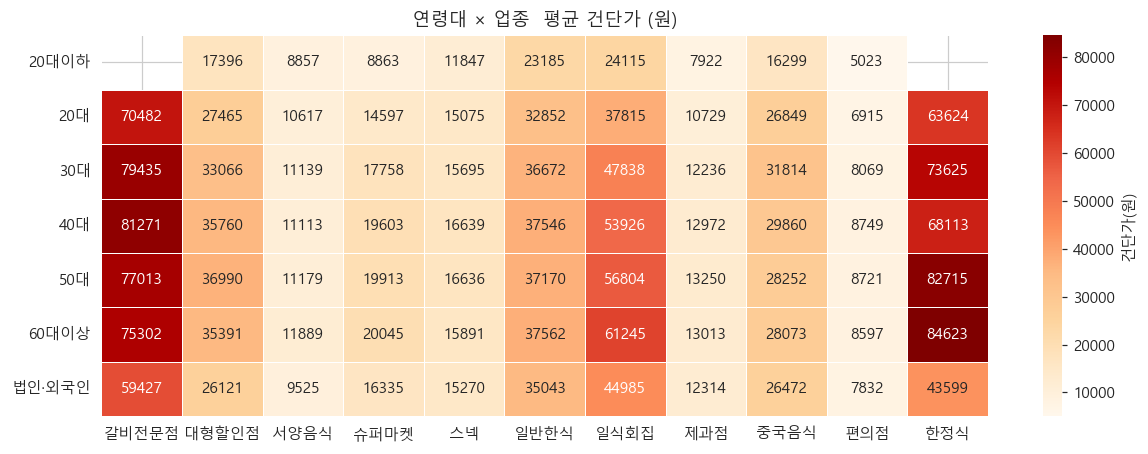

In [16]:
# 연령 × 업종 : 건단가 — 같은 업종도 나이에 따라 한 번에 쓰는 돈이 다르다
a_amt = df.pivot_table(index="연령", columns="TPBUZ_NM", values="AMT", aggfunc="sum")
a_cnt = df.pivot_table(index="연령", columns="TPBUZ_NM", values="CNT", aggfunc="sum")
unit = (a_amt / a_cnt).reindex([a for a in AGE_ORDER if a in a_amt.index])

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(unit.round(0), annot=True, fmt=".0f", cmap="OrRd",
            linewidths=.5, ax=ax, cbar_kws={"label": "건단가(원)"})
ax.set_title("연령대 × 업종  평균 건단가 (원)")
ax.set_xlabel(""); ax.set_ylabel("")
save("11_age_buz_unit")

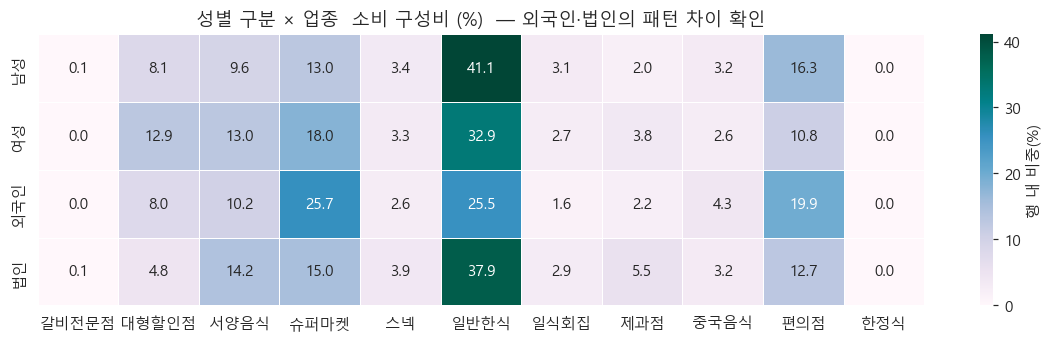

In [17]:
# 성별 × 업종 구성비
ct2 = pd.crosstab(df["성별"], df["TPBUZ_NM"], values=df["AMT"],
                  aggfunc="sum", normalize="index") * 100
ct2 = ct2.reindex(["남성", "여성", "외국인", "법인"])

fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(ct2.round(1), annot=True, fmt=".1f", cmap="PuBuGn",
            linewidths=.5, ax=ax, cbar_kws={"label": "행 내 비중(%)"})
ax.set_title("성별 구분 × 업종  소비 구성비 (%)  — 외국인·법인의 패턴 차이 확인")
ax.set_xlabel(""); ax.set_ylabel("")
save("12_gender_buz_share")

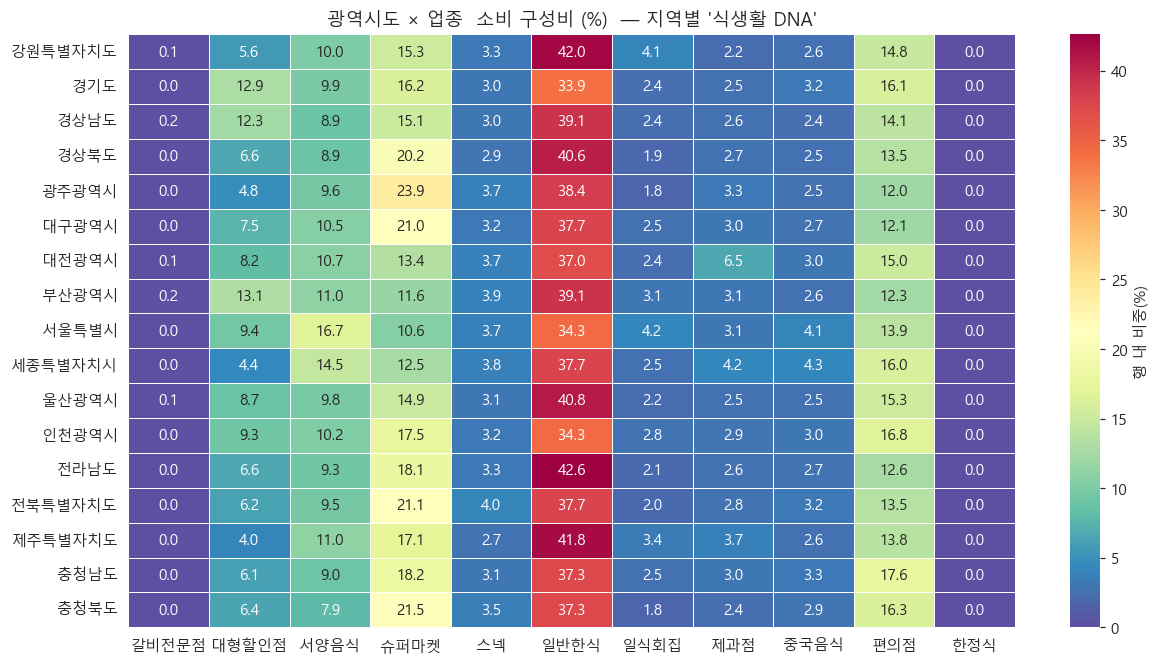

In [18]:
# 시도 × 업종 구성비 (규모 효과 제거)
ct3 = pd.crosstab(df["SIDO_NM"], df["TPBUZ_NM"], values=df["AMT"],
                  aggfunc="sum", normalize="index") * 100

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(ct3.round(1), annot=True, fmt=".1f", cmap="Spectral_r",
            linewidths=.5, ax=ax, cbar_kws={"label": "행 내 비중(%)"})
ax.set_title("광역시도 × 업종  소비 구성비 (%)  — 지역별 '식생활 DNA'")
ax.set_xlabel(""); ax.set_ylabel("")
save("13_sido_buz_share")

## 6. 핵심 지표 — 집밥 vs 외식

업종 11개는 **재료를 사서 집에서 먹는 3종**(편의점·대형할인점·슈퍼마켓)과
**밖에서 사 먹는 8종**으로 갈립니다. 여기서 두 지표를 만듭니다.

- **외식화율** = 외식 ÷ (외식 + 집밥)
- **편의점 의존도** = 편의점 ÷ 집밥 3종 — 장보기 인프라가 약한 지역일수록 높아집니다

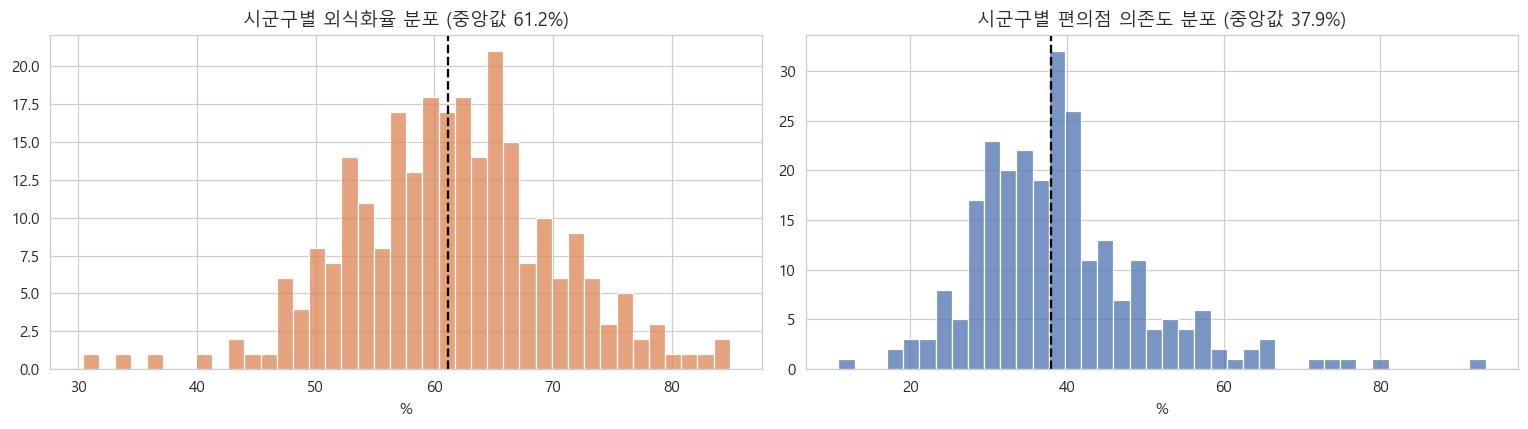

In [19]:
piv_ch = df.pivot_table(index=KEY, columns="CH", values="AMT",
                        aggfunc="sum", fill_value=0)
piv_ch["외식화율"] = piv_ch["외식"] / (piv_ch["외식"] + piv_ch["집밥(유통)"]) * 100

cvs_num = df[df["TPBUZ_NM"] == "편의점"].groupby(KEY)["AMT"].sum()
cvs_den = df[df["CH"] == "집밥(유통)"].groupby(KEY)["AMT"].sum()
piv_ch["편의점의존도"] = (cvs_num / cvs_den * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(piv_ch["외식화율"], bins=40, ax=axes[0], color="#DD8452")
axes[0].axvline(piv_ch["외식화율"].median(), color="k", ls="--")
axes[0].set_title(f"시군구별 외식화율 분포 (중앙값 {piv_ch['외식화율'].median():.1f}%)")
sns.histplot(piv_ch["편의점의존도"], bins=40, ax=axes[1], color="#4C72B0")
axes[1].axvline(piv_ch["편의점의존도"].median(), color="k", ls="--")
axes[1].set_title(f"시군구별 편의점 의존도 분포 (중앙값 {piv_ch['편의점의존도'].median():.1f}%)")
for a in axes: a.set_xlabel("%"); a.set_ylabel("")
plt.tight_layout()
save("14_ratio_dist")

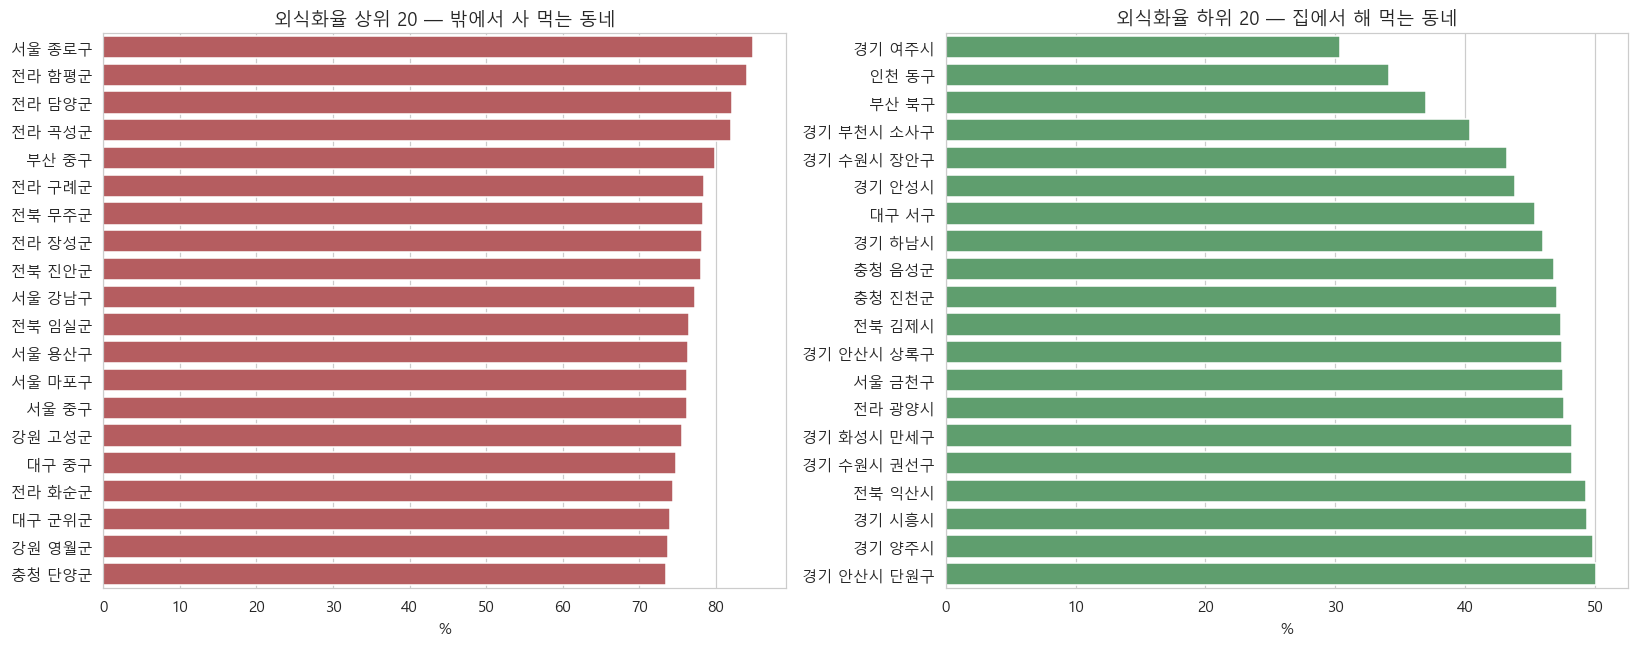

In [20]:
lab = piv_ch.copy()
lab.index = [f"{s[:2]} {c}" for s, c in lab.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = lab["외식화율"].sort_values(ascending=False).head(20)
bot = lab["외식화율"].sort_values().head(20)
sns.barplot(y=top.index, x=top.values, ax=axes[0], color="#C44E52")
axes[0].set_title("외식화율 상위 20 — 밖에서 사 먹는 동네")
sns.barplot(y=bot.index, x=bot.values, ax=axes[1], color="#55A868")
axes[1].set_title("외식화율 하위 20 — 집에서 해 먹는 동네")
for a in axes: a.set_xlabel("%"); a.set_ylabel("")
plt.tight_layout()
save("15_dineout_rank")

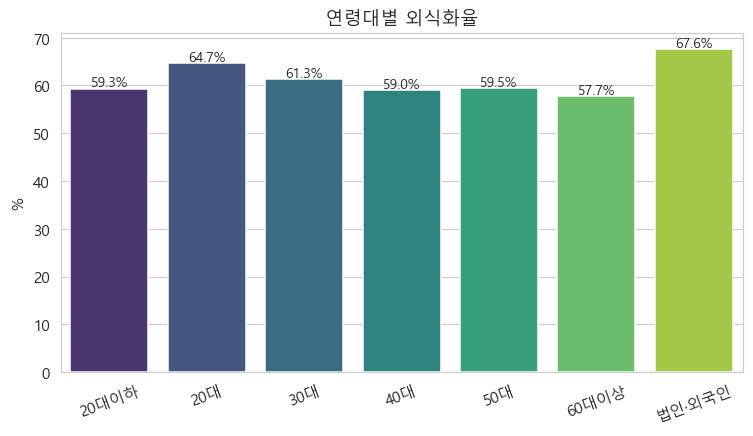

In [21]:
# 연령별 외식화율 — 세대 간 식생활 격차
age_ch = df.pivot_table(index="연령", columns="CH", values="AMT", aggfunc="sum")
age_ch["외식화율"] = age_ch["외식"] / age_ch.sum(axis=1) * 100
age_ch = age_ch.reindex([a for a in AGE_ORDER if a in age_ch.index])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=age_ch.index, y=age_ch["외식화율"], ax=ax, palette="viridis")
for i, v in enumerate(age_ch["외식화율"]):
    ax.text(i, v + .5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_title("연령대별 외식화율")
ax.set_xlabel(""); ax.set_ylabel("%")
plt.xticks(rotation=20)
save("16_age_dineout")

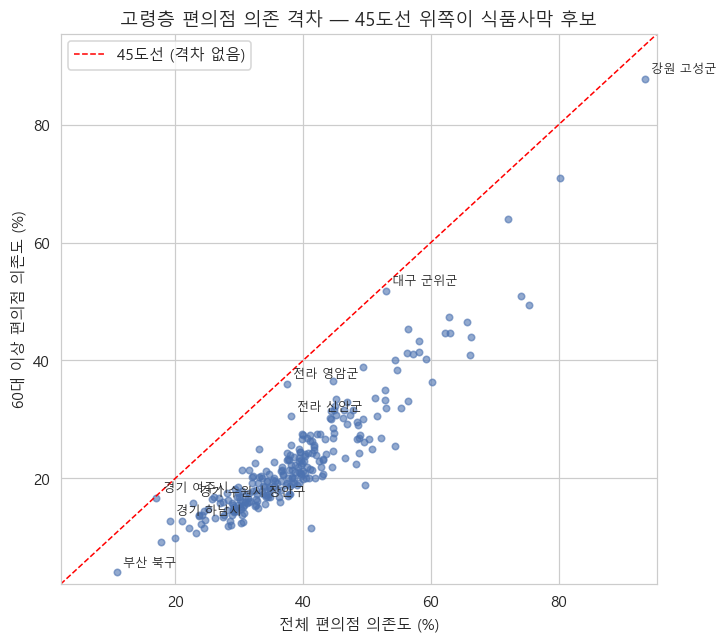

고령층 편의점 의존 격차 상위 15:


전체  60대이상   격차
SIDO_NM CCG_NM                   
경기도     여주시      17.1   16.7 -0.4
대구광역시   군위군      52.9   51.8 -1.1
전라남도    영암군      37.5   36.0 -1.5
강원특별자치도 고성군      93.4   87.8 -5.6
경기도     하남시      19.2   12.8 -6.4
부산광역시   북구       10.8    4.0 -6.8
경기도     수원시 장안구  22.7   15.9 -6.8
전라남도    신안군      38.2   30.5 -7.6
        곡성군      72.0   64.1 -7.9
강원특별자치도 홍천군      33.1   25.0 -8.1
충청남도    청양군      44.6   36.5 -8.2
전라남도    광양시      21.0   12.7 -8.3
인천광역시   동구       17.7    9.2 -8.5
경기도     안성시      30.5   21.3 -9.1
        고양시 덕양구  26.0   16.9 -9.1

In [22]:
# ★ 식품사막 후보 탐지 : 60대 이상의 편의점 의존도가 전체보다 유독 높은 지역
old = df[df["연령"] == "60대이상"]
old_dep = (old[old["TPBUZ_NM"] == "편의점"].groupby(KEY)["AMT"].sum()
           / old[old["CH"] == "집밥(유통)"].groupby(KEY)["AMT"].sum() * 100)

gap = pd.DataFrame({"전체": piv_ch["편의점의존도"], "60대이상": old_dep}).dropna()
gap["격차"] = gap["60대이상"] - gap["전체"]

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(gap["전체"], gap["60대이상"], s=18, alpha=.6, color="#4C72B0")
vals = gap[["전체", "60대이상"]]
lim = [vals.min().min() - 2, vals.max().max() + 2]
ax.plot(lim, lim, "r--", lw=1, label="45도선 (격차 없음)")
ax.set_xlim(lim); ax.set_ylim(lim)
for (s, c), r in gap.nlargest(8, "격차").iterrows():
    ax.annotate(f"{s[:2]} {c}", (r["전체"], r["60대이상"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("전체 편의점 의존도 (%)"); ax.set_ylabel("60대 이상 편의점 의존도 (%)")
ax.set_title("고령층 편의점 의존 격차 — 45도선 위쪽이 식품사막 후보")
ax.legend()
save("17_food_desert")

print("고령층 편의점 의존 격차 상위 15:")
display(gap.nlargest(15, "격차").round(1))

## 7. 외국인·법인 — 별도 축으로 살아 있는 두 개

외국인 7.4%, 법인 6.1%. 둘 다 무시할 수 없는 크기입니다.

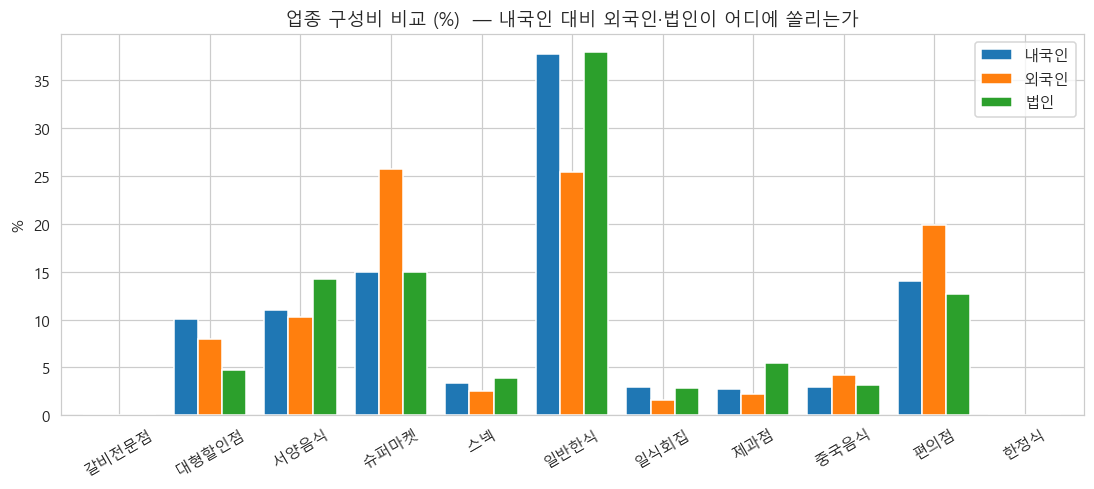

,내국인,외국인,법인,외국인-내국인,법인-내국인
TPBUZ_NM,,,,,
슈퍼마켓,15.0,25.7,15.0,10.7,-0.0
편의점,14.1,19.9,12.7,5.9,-1.4
중국음식,3.0,4.3,3.2,1.3,0.2
갈비전문점,0.1,0.0,0.1,-0.0,-0.0
한정식,0.0,0.0,0.0,-0.0,-0.0
제과점,2.8,2.2,5.5,-0.6,2.7
스넥,3.3,2.6,3.9,-0.7,0.5
서양음식,11.0,10.2,14.2,-0.8,3.2
일식회집,2.9,1.6,2.9,-1.4,-0.1


In [23]:
foreign = df[df["성별"] == "외국인"]
corp = df[df["성별"] == "법인"]
dom = df[df["성별"].isin(["남성", "여성"])]

comp = pd.DataFrame({
    "내국인": dom.groupby("TPBUZ_NM")["AMT"].sum() / dom["AMT"].sum() * 100,
    "외국인": foreign.groupby("TPBUZ_NM")["AMT"].sum() / foreign["AMT"].sum() * 100,
    "법인":   corp.groupby("TPBUZ_NM")["AMT"].sum() / corp["AMT"].sum() * 100,
}).fillna(0)

fig, ax = plt.subplots(figsize=(12, 4.5))
comp.plot(kind="bar", ax=ax, width=.8)
ax.set_title("업종 구성비 비교 (%)  — 내국인 대비 외국인·법인이 어디에 쏠리는가")
ax.set_xlabel(""); ax.set_ylabel("%")
plt.xticks(rotation=30)
save("18_foreign_corp_mix")

comp["외국인-내국인"] = (comp["외국인"] - comp["내국인"]).round(1)
comp["법인-내국인"] = (comp["법인"] - comp["내국인"]).round(1)
display(comp.round(1).sort_values("외국인-내국인", ascending=False))

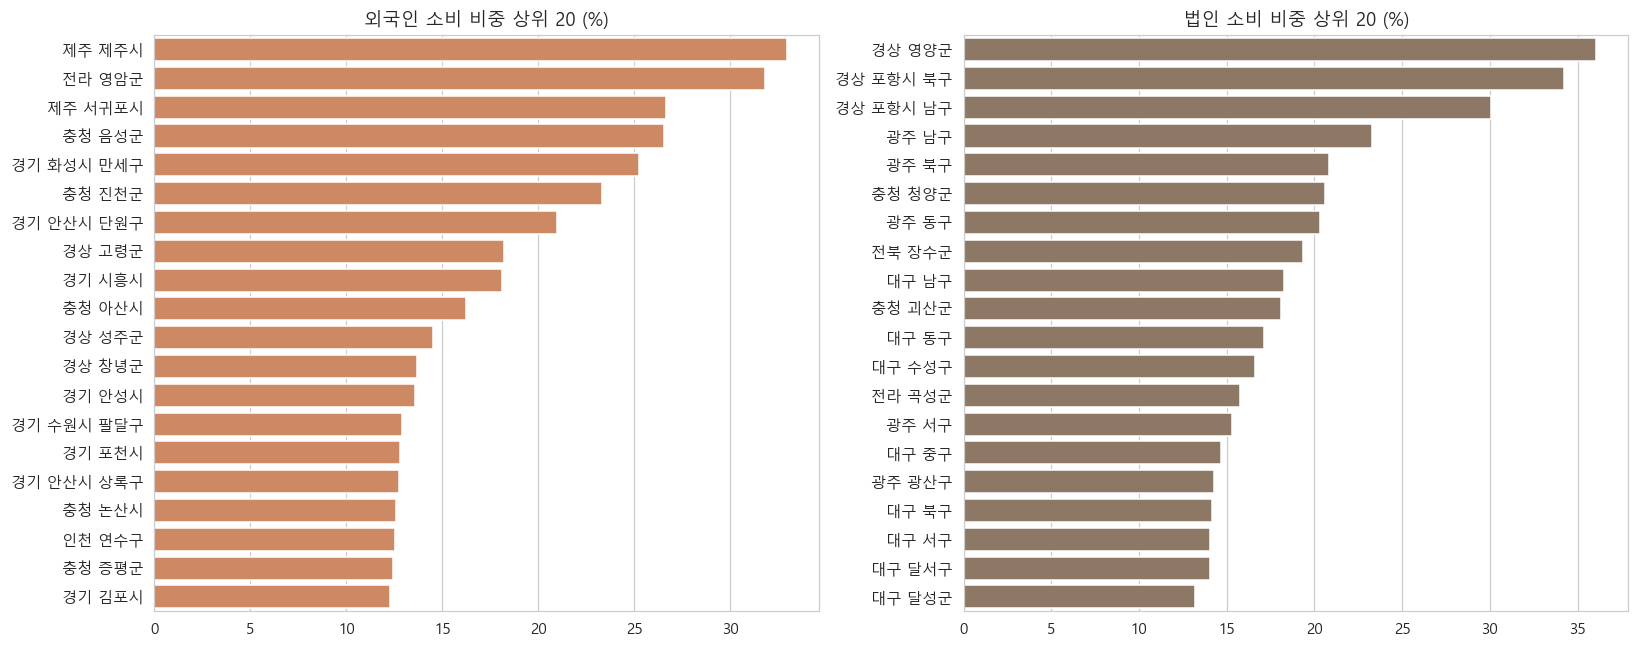

In [24]:
# 외국인·법인 소비의 지역 집중도
tot = df.groupby(KEY)["AMT"].sum()
f_share = (foreign.groupby(KEY)["AMT"].sum() / tot * 100).dropna()
c_share = (corp.groupby(KEY)["AMT"].sum() / tot * 100).dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, s, title, col in [(axes[0], f_share, "외국인 소비 비중 상위 20 (%)", "#DD8452"),
                          (axes[1], c_share, "법인 소비 비중 상위 20 (%)", "#937860")]:
    t = s.nlargest(20)
    t.index = [f"{a[:2]} {b}" for a, b in t.index]
    sns.barplot(y=t.index, x=t.values, ax=ax, color=col)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
save("19_foreign_corp_region")

## 8. 결과 저장

다음 단계(외부 데이터 결합)에서 쓸 키와 지표를 파일로 남깁니다.

In [25]:
out = Path("out"); out.mkdir(exist_ok=True)

df[KEY].drop_duplicates().sort_values(KEY).to_csv(
    out / "region_keys.csv", index=False, encoding="utf-8-sig")

df[["TPBUZ_NO", "TPBUZ_NM"]].drop_duplicates().sort_values("TPBUZ_NO").to_csv(
    out / "codebook.csv", index=False, encoding="utf-8-sig")

piv_ch.join(gap["격차"].rename("고령편의점격차")).round(2).to_csv(
    out / "region_metrics.csv", encoding="utf-8-sig")

print("저장 완료:", [p.name for p in out.iterdir()])
print("그림:", len(list(FIG.iterdir())), "개")

저장 완료: ['codebook.csv', 'region_keys.csv', 'region_metrics.csv']
그림: 19 개


---

## 다음 단계

이 노트북에서 확인해야 할 것:

1. **09번 그림** — 서울 중구·종로구가 상위권인가? → `CCG_NM`이 가맹점 소재지인지 판정
2. **10·11번 히트맵** — 연령 × 업종에서 눈에 띄는 칸이 있는가?
3. **17번 산점도** — 45도선에서 크게 벗어난 지역이 있는가? → 식품사막 후보

그다음 붙일 외부 데이터:

- 행정안전부 주민등록 인구통계 (시군구 × 성 × 5세 단위, 월별)
- 소상공인시장진흥공단 상가업소 정보 (슈퍼·마트 점포 수)
- 행정표준코드 (시군구 코드 매핑)